<a href="https://colab.research.google.com/github/nancyluka200/nancyluka/blob/main/HW1_Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import userdata
from groq import Groq

api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=api_key)

response = client.chat.completions.create(
    model="llama-3.1-8b-instant",
    messages=[{"role": "user", "content": "Say hello in one sentence."}]
)
print(response.choices[0].message.content)


Hello, it's nice to assist you with any questions or information you may need.


In [6]:
!pip install -q groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 8.3 MB/s eta 0:00:00


In [14]:
from google.colab import files
uploaded = files.upload()

Saving article10.txt to article10 (1).txt
Saving article9.txt to article9 (1).txt
Saving article8.txt to article8 (1).txt
Saving article7.txt to article7 (1).txt
Saving article1.txt to article1 (1).txt
Saving article6.txt to article6 (1).txt
Saving article5.txt to article5 (1).txt
Saving article4.txt to article4 (1).txt
Saving article3.txt to article3 (1).txt
Saving article2.txt to article2 (1).txt


In [19]:
import glob
for f in sorted(glob.glob("*.txt")):
    print(repr(f))

'article1.txt'
'article10.txt'
'article2.txt'
'article3.txt'
'article4.txt'
'article5.txt'
'article6.txt'
'article7.txt'
'article8.txt'
'article9.txt'


In [20]:
import json

summaries = {}
for filepath in sorted(glob.glob("*.txt")):
    with open(filepath, "r", encoding="utf-8") as f:
        article_text = f.read()

    prompt = f"Summarize the following article in 2-3 sentences:\n\n{article_text}"
    response = client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=[{"role": "user", "content": prompt}]
    )
    summary = response.choices[0].message.content.strip()

    print(f"\n=== {filepath} ===")
    print(summary)

    summaries[filepath] = summary

print(f"\nDone. Total summaries: {len(summaries)}")



=== article1.txt ===
Here is a 3-sentence summary of the article:

Frederic Eugene Ives' invention of the halftone printing process is a prime example of the creative process, which involves making new connections between old ideas. According to advertising executive James Webb Young, creative ideas occur when we develop new combinations of old elements, and this process typically unfolds in five stages: gathering new material, working over the materials in one's mind, stepping away from the problem, letting the idea return, and shaping and developing the idea based on feedback. By following these five steps, anyone can become more creative and generate innovative ideas to solve problems in their work and personal lives.

=== article10.txt ===
Here's a summary of the article in 2-3 sentences:

The importance of luck versus hard work in achieving success is a complex issue, and James Clear argues that the answer lies in the distinction between absolute and relative success. Absolute su

In [22]:
with open("summaries.json", "w", encoding="utf-8") as f:
    json.dump(summaries, f, indent=2, ensure_ascii=False)

print(f"Saved {len(summaries)} summaries to summaries.json")
files.download("summaries.json")

Saved 10 summaries to summaries.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Homework 1.2 - LLM-generated points and shortest path


In [23]:
!pip install -q groq

In [ ]:
from google.colab import userdata
from groq import Groq

api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=api_key)

print("Connected!")

Connected!


In [ ]:
import json

prompt = """Generate exactly 20 random 2D points with x and y coordinates between 0 and 100.
Output ONLY valid JSON, nothing else, in this exact format:
[{"x": 12.5, "y": 34.2}, {"x": 56.1, "y": 78.9}, ...]
"""

response = client.chat.completions.create(
    model="llama-3.1-8b-instant",
    messages=[{"role": "user", "content": prompt}]
)

points_text = response.choices[0].message.content.strip()
print(points_text)

[{"x": 91.4, "y": 31.9}, {"x": 72.0, "y": 19.5}, {"x": 85.6, "y": 68.3}, {"x": 42.1, "y": 82.9}, {"x": 39.7, "y": 13.8}, {"x": 11.2, "y": 46.1}, {"x": 63.2, "y": 26.0}, {"x": 75.4, "y": 54.0}, {"x": 98.9, "y": 85.1}, {"x": 59.3, "y": 49.2}, {"x": 48.5, "y": 61.9}, {"x": 89.6, "y": 24.7}, {"x": 35.4, "y": 73.1}, {"x": 22.5, "y": 91.3}, {"x": 77.9, "y": 40.3}, {"x": 66.0, "y": 58.1}, {"x": 51.8, "y": 69.5}, {"x": 31.9, "y": 80.1}, {"x": 83.2, "y": 17.2}, {"x": 14.8, "y": 27.9}]


In [ ]:
import json

# Parse the JSON text into Python data
points = json.loads(points_text)

print(f"LLM returned {len(points)} points")

# Enforce exactly 20
points = points[:20]

print(f"Using {len(points)} points")
print(points)

LLM returned 20 points
Using 20 points
[{'x': 91.4, 'y': 31.9}, {'x': 72.0, 'y': 19.5}, {'x': 85.6, 'y': 68.3}, {'x': 42.1, 'y': 82.9}, {'x': 39.7, 'y': 13.8}, {'x': 11.2, 'y': 46.1}, {'x': 63.2, 'y': 26.0}, {'x': 75.4, 'y': 54.0}, {'x': 98.9, 'y': 85.1}, {'x': 59.3, 'y': 49.2}, {'x': 48.5, 'y': 61.9}, {'x': 89.6, 'y': 24.7}, {'x': 35.4, 'y': 73.1}, {'x': 22.5, 'y': 91.3}, {'x': 77.9, 'y': 40.3}, {'x': 66.0, 'y': 58.1}, {'x': 51.8, 'y': 69.5}, {'x': 31.9, 'y': 80.1}, {'x': 83.2, 'y': 17.2}, {'x': 14.8, 'y': 27.9}]


In [ ]:
path_prompt = f"""Here are 20 points with their index and coordinates:
{json.dumps([{"index": i, "x": p["x"], "y": p["y"]} for i, p in enumerate(points)], indent=2)}

Task: Find a short route visiting every point exactly once, starting from any point (like a traveling salesman route). Use a nearest-neighbor approach: at each step, go to the closest unvisited point.

Respond with ONLY a JSON array of all 20 indices in visiting order. Do NOT include code, explanations, markdown formatting, or any other text.
Your entire response must be exactly this format and nothing else:
[0, 5, 3, 1, 7, 2, ...]
"""

path_response = client.chat.completions.create(
    model="llama-3.1-8b-instant",
    messages=[{"role": "user", "content": path_prompt}]
)

path_text = path_response.choices[0].message.content.strip()
print(path_text)

[0, 5, 3, 1, 7, 2, 6, 9, 10, 16, 15, 8, 11, 4, 19, 13, 12, 17, 18, 14]


In [ ]:
path = json.loads(path_text)

print(f"Path length: {len(path)}")
print(f"Valid (all 20 unique indices): {sorted(path) == list(range(20))}")
print(path)

Path length: 20
Valid (all 20 unique indices): True
[0, 5, 3, 1, 7, 2, 6, 9, 10, 16, 15, 8, 11, 4, 19, 13, 12, 17, 18, 14]


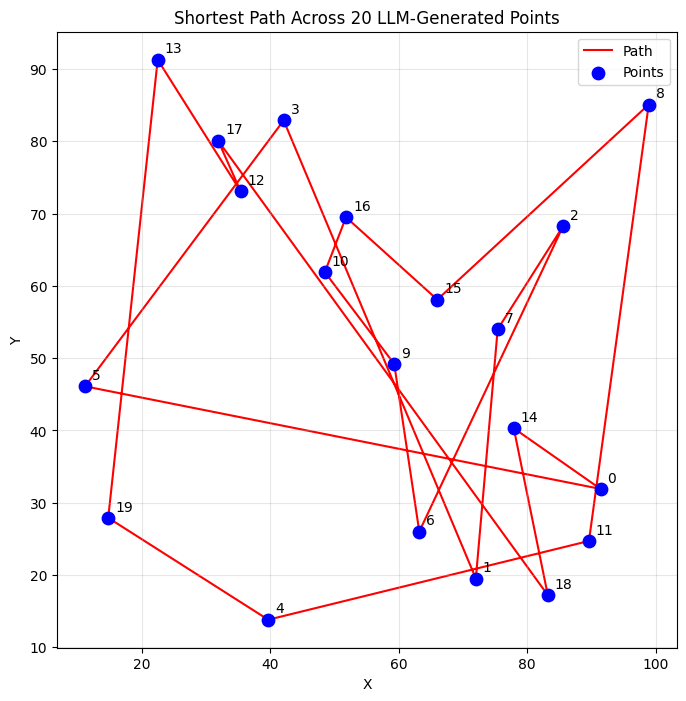

In [ ]:
import matplotlib.pyplot as plt

xs = [p["x"] for p in points]
ys = [p["y"] for p in points]

plt.figure(figsize=(8, 8))

path_xs = [points[i]["x"] for i in path]
path_ys = [points[i]["y"] for i in path]

path_xs.append(points[path[0]]["x"])
path_ys.append(points[path[0]]["y"])

plt.plot(path_xs, path_ys, color="red", linewidth=1.5, zorder=1, label="Path")
plt.scatter(xs, ys, color="blue", s=80, zorder=2, label="Points")

for i, (x, y) in enumerate(zip(xs, ys)):
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5))

plt.title("Shortest Path Across 20 LLM-Generated Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()